# EN4554 Deep Learning for Vision — Assignment 2: CNNs

**Name:** Mohamed Irshad Nadha
**Index number:** 220409J
**GitHub:** https://github.com/NadhaIrshad/EN4554-Deep-Learning-for-Vision

**AI-tool acknowledgement.** Claude (Anthropic, via Claude Code) was used to help write and debug the code in this notebook. I have read and understood every part of it.

**Compute note.** The notebook detects the device. On a CUDA GPU (e.g. Colab T4) it uses the full budget (`FULL=True`). On a CPU-only laptop, the expensive experiments run on training subsets and with fewer epochs (see the `BUDGET` table printed below). The results in this PDF were produced on a **Colab T4 GPU** with the full budget. Every result is cached in `results/` so the notebook can be re-rendered without retraining.

## 0. Setup: data, seeds, helpers

In [1]:
import os, time, json, math, random, copy
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
FULL = DEVICE.type == 'cuda'
SMOKE = os.environ.get('A2_SMOKE') == '1'          # tiny settings for a quick end-to-end test of the code
if DEVICE.type == 'cpu':
    torch.set_num_threads(os.cpu_count())
RESULTS = 'results_smoke' if SMOKE else 'results'
os.makedirs(RESULTS, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

if FULL:   # Colab T4 budget
    BUDGET = dict(t1_epochs=20, t2_n=45000, t2_epochs=15, t3a_epochs=60, t3b_n=45000, t3b_epochs=30,
                  t4_ablate_n=45000, t4_ablate_epochs=20, t4_final_epochs=20)
else:      # CPU-only laptop budget
    BUDGET = dict(t1_epochs=20, t2_n=20000, t2_epochs=8, t3a_epochs=30, t3b_n=10000, t3b_epochs=12,
                  t4_ablate_n=15000, t4_ablate_epochs=10, t4_final_epochs=15)
if SMOKE:
    BUDGET = dict(t1_epochs=1, t2_n=1000, t2_epochs=1, t3a_epochs=2, t3b_n=500, t3b_epochs=1,
                  t4_ablate_n=2000, t4_ablate_epochs=1, t4_final_epochs=1)
print('device:', DEVICE, '| torch', torch.__version__, '| FULL =', FULL, '| SMOKE =', SMOKE)
print('BUDGET:', BUDGET)


def set_seed(s=0):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)


def cached(name, fn):
    """Run fn() once and store its (JSON-serialisable) result; later runs load it."""
    path = f'{RESULTS}/{name}.json'
    if os.path.exists(path):
        with open(path) as f:
            return json.load(f)
    out = fn()
    with open(path, 'w') as f:
        json.dump(out, f)
    return out

device: cuda | torch 2.11.0+cu130 | FULL = True | SMOKE = False
BUDGET: {'t1_epochs': 20, 't2_n': 45000, 't2_epochs': 15, 't3a_epochs': 60, 't3b_n': 45000, 't3b_epochs': 30, 't4_ablate_n': 45000, 't4_ablate_epochs': 20, 't4_final_epochs': 20}


**Data.** The 50k CIFAR-10 training images are split (with a fixed permutation) into 45k train and 5k validation images. Each channel is normalised with the mean and standard deviation of the 45k training images. The test set is **not loaded here**; it is loaded only once, in Task 4.

In [2]:
set_seed(0)
_train = torchvision.datasets.CIFAR10('./data', train=True, download=True)
X_all = torch.tensor(_train.data).permute(0, 3, 1, 2).float() / 255.
Y_all = torch.tensor(_train.targets).long()
perm = torch.randperm(50000, generator=torch.Generator().manual_seed(0))
tr_idx, va_idx = perm[:45000], perm[45000:]
MEAN = X_all[tr_idx].mean(dim=(0, 2, 3))
STD = X_all[tr_idx].std(dim=(0, 2, 3))
normalize = lambda x: (x - MEAN[None, :, None, None]) / STD[None, :, None, None]
Xtr, Ytr = normalize(X_all[tr_idx]).to(DEVICE), Y_all[tr_idx].to(DEVICE)
Xva, Yva = normalize(X_all[va_idx]).to(DEVICE), Y_all[va_idx].to(DEVICE)
del X_all, _train
CLASSES = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')
print('train', tuple(Xtr.shape), 'val', tuple(Xva.shape))
print('mean', MEAN.numpy().round(4), 'std', STD.numpy().round(4))
print('normalised train mean/std:', Xtr.mean((0, 2, 3)).cpu().numpy().round(3), Xtr.std((0, 2, 3)).cpu().numpy().round(3))

100%|██████████| 170M/170M [1:01:26<00:00, 46.2kB/s]


train (45000, 3, 32, 32) val (5000, 3, 32, 32)
mean [0.4912 0.482  0.4464] std [0.2472 0.2436 0.2617]
normalised train mean/std: [0. 0. 0.] [1. 1. 1.]


Shared training utilities. Data stays in memory as tensors, and augmentation runs on whole mini-batches (vectorised), which avoids slow per-image `DataLoader` workers. Random flip, random crop, **cutout** and **mixup** are all implemented by hand.

In [3]:
def batches(X, Y, bs, shuffle=True):
    idx = torch.randperm(len(X), device=X.device) if shuffle else torch.arange(len(X), device=X.device)
    for i in range(0, len(X), bs):
        j = idx[i:i + bs]
        yield X[j], Y[j]


def random_flip(x):
    m = torch.rand(x.size(0), 1, 1, 1, device=x.device) < 0.5
    return torch.where(m, x.flip(3), x)


def random_crop(x, pad=4):
    """Zero-pad by `pad` and take a random 32x32 crop per image (vectorised gather)."""
    B, C, H, W = x.shape
    xp = F.pad(x, (pad, pad, pad, pad))
    i = torch.randint(0, 2 * pad + 1, (B,), device=x.device)
    j = torch.randint(0, 2 * pad + 1, (B,), device=x.device)
    rows = (i[:, None] + torch.arange(H, device=x.device))[:, None, :, None]
    cols = (j[:, None] + torch.arange(W, device=x.device))[:, None, None, :]
    return xp[torch.arange(B, device=x.device)[:, None, None, None],
              torch.arange(C, device=x.device)[None, :, None, None], rows, cols]


def cutout(x, size=16):
    """Zero a size x size square at a random centre (may be partly outside the image)."""
    B, C, H, W = x.shape
    cy = torch.randint(0, H, (B, 1, 1), device=x.device)
    cx = torch.randint(0, W, (B, 1, 1), device=x.device)
    ys = torch.arange(H, device=x.device).view(1, H, 1)
    xs = torch.arange(W, device=x.device).view(1, 1, W)
    inside = (ys >= cy - size // 2) & (ys < cy + size // 2) & (xs >= cx - size // 2) & (xs < cx + size // 2)
    return x * (~inside).unsqueeze(1).float()      # 0 = channel mean after normalisation


def mixup(x, y, alpha=1.0):
    lam = float(np.random.beta(alpha, alpha))
    p = torch.randperm(x.size(0), device=x.device)
    return lam * x + (1 - lam) * x[p], y, y[p], lam


def make_aug(flip_crop=False, cut=False):
    def aug(x):
        if flip_crop:
            x = random_crop(random_flip(x))
        if cut:
            x = cutout(x)
        return x
    return aug if (flip_crop or cut) else None


@torch.no_grad()
def evaluate(model, X, Y, bs=1000):
    model.eval()
    loss, correct = 0.0, 0
    for xb, yb in batches(X, Y, bs, shuffle=False):
        out = model(xb)
        loss += F.cross_entropy(out, yb, reduction='sum').item()
        correct += (out.argmax(1) == yb).sum().item()
    return loss / len(X), correct / len(X)


def fit(model, opt, epochs, Xt, Yt, bs=128, sched=None, aug=None, mixup_alpha=0.0,
        label_smoothing=0.0, n_train_eval=5000, tag=''):
    """Generic training loop. Train accuracy/loss is re-evaluated on clean (non-augmented)
    training images in eval mode so that the train/val gap is measured fairly."""
    model.to(DEVICE)
    steps = epochs * math.ceil(len(Xt) / bs)
    if sched == 'cosine':
        sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=steps)
    elif sched == 'onecycle':
        sch = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=[g['lr'] for g in opt.param_groups],
                                                  total_steps=steps, pct_start=0.25)
    else:
        sch = None
    H = dict(iter_loss=[], train_loss_running=[], train_loss=[], train_acc=[], val_loss=[], val_acc=[], diverged=False)
    Xe, Ye = Xt[:n_train_eval], Yt[:n_train_eval]
    for ep in range(epochs):
        model.train(); t0 = time.time(); run = []
        for xb, yb in batches(Xt, Yt, bs):
            if aug is not None:
                xb = aug(xb)
            if mixup_alpha > 0:
                xb, ya, yb2, lam = mixup(xb, yb, mixup_alpha)
                out = model(xb)
                loss = lam * F.cross_entropy(out, ya, label_smoothing=label_smoothing) + \
                       (1 - lam) * F.cross_entropy(out, yb2, label_smoothing=label_smoothing)
            else:
                loss = F.cross_entropy(model(xb), yb, label_smoothing=label_smoothing)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            if sch is not None:
                sch.step()
            run.append(loss.item())
            if not math.isfinite(run[-1]):
                break
        H['iter_loss'] += run
        H['train_loss_running'].append(float(np.mean(run)))
        if not math.isfinite(run[-1]):
            H['diverged'] = True
            print(f'[{tag}] diverged at epoch {ep + 1}')
            break
        tl, ta = evaluate(model, Xe, Ye)
        vl, va = evaluate(model, Xva, Yva)
        H['train_loss'].append(tl); H['train_acc'].append(ta); H['val_loss'].append(vl); H['val_acc'].append(va)
        print(f'[{tag}] ep {ep + 1:2d}/{epochs}  run-loss {H["train_loss_running"][-1]:.3f}  '
              f'train {tl:.3f}/{ta:.3f}  val {vl:.3f}/{va:.3f}  ({time.time() - t0:.0f}s)')
    return H


def n_params(m):
    return sum(p.numel() for p in m.parameters())

---
## Task 1: Backpropagation without autograd

### (a) Layers with explicit `forward` / `backward`
Each layer caches what it needs in `forward` and returns $\partial L/\partial(\text{input})$ in `backward`. For a linear layer $Y = XW + b$ with upstream gradient $G=\partial L/\partial Y$:
$\;\partial L/\partial W = X^\top G,\; \partial L/\partial b = \sum_n G_n,\; \partial L/\partial X = G W^\top$.
For softmax cross-entropy averaged over $N$ samples, $\partial L/\partial z = (\mathrm{softmax}(z) - \mathrm{onehot}(y))/N$.

In [4]:
class Linear:
    def __init__(self, d_in, d_out, init='he', dtype=torch.float32):
        std = math.sqrt(2.0 / d_in) if init == 'he' else math.sqrt(2.0 / (d_in + d_out))   # He or Xavier
        self.W = torch.randn(d_in, d_out, dtype=dtype, device=DEVICE) * std
        self.b = torch.zeros(d_out, dtype=dtype, device=DEVICE)

    def forward(self, x):
        self.x = x
        return x @ self.W + self.b

    def backward(self, g):
        self.dW = self.x.T @ g
        self.db = g.sum(0)
        return g @ self.W.T


class ReLU:
    def forward(self, x):
        self.mask = (x > 0).to(x.dtype)
        return x * self.mask

    def backward(self, g):
        return g * self.mask


class Sigmoid:
    def forward(self, x):
        self.s = 1.0 / (1.0 + torch.exp(-x))
        return self.s

    def backward(self, g):
        return g * self.s * (1 - self.s)


class SoftmaxCrossEntropy:
    def forward(self, z, y):
        z = z - z.max(dim=1, keepdim=True).values                    # numerical stability
        logp = z - torch.log(torch.exp(z).sum(dim=1, keepdim=True))
        self.p, self.y = torch.exp(logp), y
        return -logp[torch.arange(len(y)), y].mean()

    def backward(self):
        g = self.p.clone()
        g[torch.arange(len(self.y)), self.y] -= 1.0
        return g / len(self.y)


class MLP:
    def __init__(self, sizes, act='relu', init='he', dtype=torch.float32):
        self.layers = []
        for i in range(len(sizes) - 1):
            self.layers.append(Linear(sizes[i], sizes[i + 1], init, dtype))
            if i < len(sizes) - 2:
                self.layers.append(ReLU() if act == 'relu' else Sigmoid())
        self.loss_fn = SoftmaxCrossEntropy()

    @property
    def linears(self):
        return [l for l in self.layers if isinstance(l, Linear)]

    def forward(self, x):
        for l in self.layers:
            x = l.forward(x)
        return x

    def loss(self, x, y):
        return self.loss_fn.forward(self.forward(x), y)

    def backward(self):
        g = self.loss_fn.backward()
        for l in reversed(self.layers):
            g = l.backward(g)
        return g                               # gradient w.r.t. the input

    def sgd_step(self, lr):
        for l in self.linears:
            l.W -= lr * l.dW
            l.b -= lr * l.db

### (b) Gradient check: autograd and centred finite differences
The check runs in float64 on a small MLP (32-24-16-10, ReLU) with a batch of 8 random inputs, so that every parameter can be checked with centred differences $\frac{L(\theta+\epsilon)-L(\theta-\epsilon)}{2\epsilon}$, $\epsilon=10^{-6}$. The relative error is $\|g_1-g_2\|_2 / (\|g_1\|_2+\|g_2\|_2)$. A second check compares against autograd on the real CIFAR-10 MLP (3072-512-256-10) with a mini-batch of real images.

In [5]:
def autograd_grads(mlp, x, y, act='relu'):
    """Same network, rebuilt from torch ops so autograd can differentiate it."""
    Ws = [l.W.clone().requires_grad_(True) for l in mlp.linears]
    bs = [l.b.clone().requires_grad_(True) for l in mlp.linears]
    xi = x.clone().requires_grad_(True)
    h = xi
    for k, (W, b) in enumerate(zip(Ws, bs)):
        h = h @ W + b
        if k < len(Ws) - 1:
            h = torch.relu(h) if act == 'relu' else torch.sigmoid(h)
    F.cross_entropy(h, y).backward()
    return [W.grad for W in Ws], [b.grad for b in bs], xi.grad


def finite_diff(mlp, x, y, tensor, eps=1e-6):
    g = torch.zeros_like(tensor)
    flat, gflat = tensor.view(-1), g.view(-1)
    for i in range(flat.numel()):
        old = flat[i].item()
        flat[i] = old + eps; lp = mlp.loss(x, y).item()
        flat[i] = old - eps; lm = mlp.loss(x, y).item()
        flat[i] = old
        gflat[i] = (lp - lm) / (2 * eps)
    return g


rel_err = lambda a, b: ((a - b).norm() / (a.norm() + b.norm()).clamp_min(1e-30)).item()

set_seed(0)
small = MLP([32, 24, 16, 10], dtype=torch.float64)
xs = torch.randn(8, 32, dtype=torch.float64, device=DEVICE)
ys = torch.randint(0, 10, (8,), device=DEVICE)
small.loss(xs, ys); dx_mine = small.backward()
gW_auto, gb_auto, dx_auto = autograd_grads(small, xs, ys)

rows = []
for k, l in enumerate(small.linears):
    for name, mine, auto, tens in [(f'W{k + 1}', l.dW, gW_auto[k], l.W), (f'b{k + 1}', l.db, gb_auto[k], l.b)]:
        fd = finite_diff(small, xs, ys, tens)
        rows.append((name, tuple(tens.shape), rel_err(mine, auto), torch.allclose(mine, auto),
                     rel_err(mine, fd), torch.allclose(mine, fd, rtol=1e-5, atol=1e-7)))
fd_x = finite_diff(small, xs, ys, xs)
rows.append(('input x', tuple(xs.shape), rel_err(dx_mine, dx_auto), torch.allclose(dx_mine, dx_auto),
             rel_err(dx_mine, fd_x), torch.allclose(dx_mine, fd_x, rtol=1e-5, atol=1e-7)))

print(f'{"tensor":8s} {"shape":10s} {"rel.err vs autograd":>20s} {"allclose":>9s} {"rel.err vs FD":>15s} {"allclose":>9s}')
for r in rows:
    print(f'{r[0]:8s} {str(r[1]):10s} {r[2]:20.2e} {str(r[3]):>9s} {r[4]:15.2e} {str(r[5]):>9s}')

# Second check: real CIFAR batch, full-size MLP, float32, against autograd
set_seed(0)
big = MLP([3072, 512, 256, 10])
xb, yb = Xtr[:256].reshape(256, -1), Ytr[:256]
big.loss(xb, yb); big.backward()
gW_auto, gb_auto, _ = autograd_grads(big, xb, yb)
print('\nCIFAR MLP 3072-512-256-10 (float32) vs autograd:')
for k, l in enumerate(big.linears):
    print(f'  W{k + 1}: rel.err {rel_err(l.dW, gW_auto[k]):.2e} allclose {torch.allclose(l.dW, gW_auto[k], atol=1e-6)}   '
          f'b{k + 1}: rel.err {rel_err(l.db, gb_auto[k]):.2e} allclose {torch.allclose(l.db, gb_auto[k], atol=1e-6)}')

tensor   shape       rel.err vs autograd  allclose   rel.err vs FD  allclose
W1       (32, 24)               0.00e+00      True        1.37e-09      True
b1       (24,)                  0.00e+00      True        8.82e-10      True
W2       (24, 16)               0.00e+00      True        7.62e-10      True
b2       (16,)                  0.00e+00      True        9.88e-10      True
W3       (16, 10)               0.00e+00      True        4.79e-10      True
b3       (10,)                  0.00e+00      True        8.30e-10      True
input x  (8, 32)                0.00e+00      True        3.15e-09      True

CIFAR MLP 3072-512-256-10 (float32) vs autograd:
  W1: rel.err 0.00e+00 allclose True   b1: rel.err 0.00e+00 allclose True
  W2: rel.err 0.00e+00 allclose True   b2: rel.err 0.00e+00 allclose True
  W3: rel.err 0.00e+00 allclose True   b3: rel.err 0.00e+00 allclose True


**Interpretation (b).** The hand-written backward pass is correct.
* **Against autograd**, the relative error is 0 (to machine precision) for every weight, bias and the input gradient, and `torch.allclose` returns `True` everywhere. This holds both for the float64 toy network and for the full 3072-512-256-10 CIFAR MLP in float32. That is expected, because the analytic formulas ($X^\top G$, $\sum_n G_n$, $GW^\top$, $(\mathrm{softmax}-\mathrm{onehot})/N$) are exactly the operations autograd itself performs.
* **Against centred finite differences**, the relative errors are $5\times10^{-10}$ to $3\times10^{-9}$, and `allclose` is `True`. A centred difference has truncation error $O(\epsilon^2)$ plus round-off of order $\varepsilon_{\text{mach}}/\epsilon$. With $\epsilon=10^{-6}$ in float64, an error around $10^{-9}$ is the accuracy we should expect. A bug, such as a missing transpose or a missing $1/N$, would give relative errors of order $10^{-1}$ or larger.
* The check works only because the probes rarely cross a ReLU kink. At a kink the function is not differentiable and the finite difference would disagree.

### (c) Training the hand-written MLP with SGD on flattened CIFAR-10
Architecture 3072-512-256-10 (ReLU, He initialisation), mini-batch 128, plain SGD with lr = 0.02 for 20 epochs. No autograd is used anywhere in training.

epoch  1  train loss 1.478 acc 0.481 | val loss 1.629 acc 0.425  (0.5s)
epoch  2  train loss 1.357 acc 0.531 | val loss 1.561 acc 0.444  (0.4s)
epoch  3  train loss 1.256 acc 0.558 | val loss 1.535 acc 0.469  (0.4s)
epoch  4  train loss 1.151 acc 0.608 | val loss 1.483 acc 0.488  (0.4s)
epoch  5  train loss 1.104 acc 0.620 | val loss 1.493 acc 0.487  (0.4s)
epoch  6  train loss 1.016 acc 0.653 | val loss 1.465 acc 0.495  (0.4s)
epoch  7  train loss 0.985 acc 0.660 | val loss 1.494 acc 0.493  (0.4s)
epoch  8  train loss 0.895 acc 0.701 | val loss 1.467 acc 0.498  (0.4s)
epoch  9  train loss 0.847 acc 0.718 | val loss 1.471 acc 0.514  (0.4s)
epoch 10  train loss 0.815 acc 0.726 | val loss 1.527 acc 0.495  (0.4s)
epoch 11  train loss 0.772 acc 0.748 | val loss 1.555 acc 0.494  (0.4s)
epoch 12  train loss 0.740 acc 0.755 | val loss 1.560 acc 0.496  (0.4s)
epoch 13  train loss 0.685 acc 0.775 | val loss 1.590 acc 0.493  (0.4s)
epoch 14  train loss 0.635 acc 0.794 | val loss 1.583 acc 0.501 

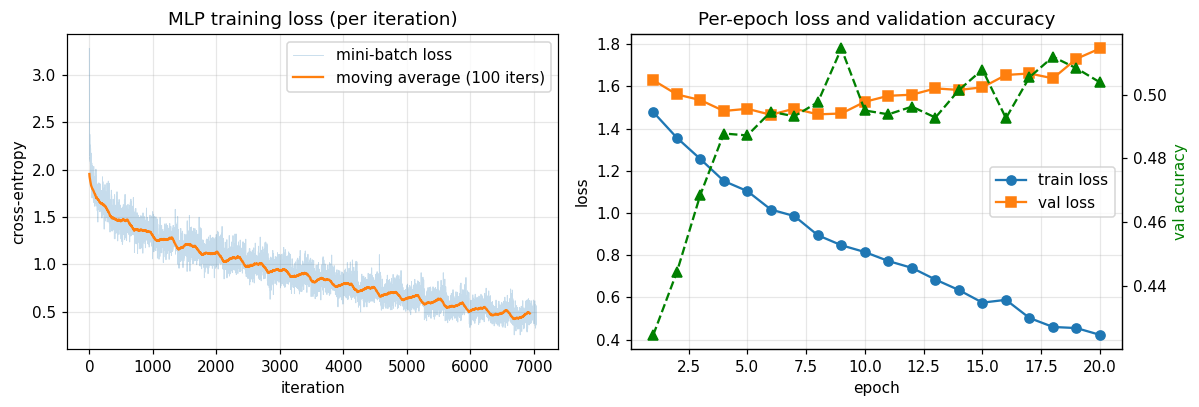

Final validation accuracy: 50.38%   (best 51.44% at epoch 9)


In [6]:
def train_numpy_mlp():
    set_seed(0)
    net = MLP([3072, 512, 256, 10])
    Xf, Xvf = Xtr.reshape(len(Xtr), -1), Xva.reshape(len(Xva), -1)
    lr, H = 0.02, dict(iter_loss=[], train_loss=[], val_loss=[], val_acc=[], train_acc=[])

    def eval_split(X, Y):
        losses, correct = [], 0
        for i in range(0, len(X), 1000):
            z = net.forward(X[i:i + 1000])
            losses.append(net.loss_fn.forward(z, Y[i:i + 1000]).item() * len(z))
            correct += (z.argmax(1) == Y[i:i + 1000]).sum().item()
        return sum(losses) / len(X), correct / len(X)

    for ep in range(BUDGET['t1_epochs']):
        t0 = time.time()
        for xb, yb in batches(Xf, Ytr, 128):
            H['iter_loss'].append(net.loss(xb, yb).item())
            net.backward(); net.sgd_step(lr)
        tl, ta = eval_split(Xf[:10000], Ytr[:10000])
        vl, va = eval_split(Xvf, Yva)
        for k, v in zip(['train_loss', 'train_acc', 'val_loss', 'val_acc'], [tl, ta, vl, va]):
            H[k].append(v)
        print(f'epoch {ep + 1:2d}  train loss {tl:.3f} acc {ta:.3f} | val loss {vl:.3f} acc {va:.3f}  ({time.time() - t0:.1f}s)')
    return H


H1 = cached('t1c_mlp', train_numpy_mlp)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
it = np.array(H1['iter_loss'])
ax[0].plot(it, alpha=0.25, lw=0.6, label='mini-batch loss')
ax[0].plot(np.convolve(it, np.ones(100) / 100, mode='valid'), label='moving average (100 iters)')
ax[0].set(xlabel='iteration', ylabel='cross-entropy', title='MLP training loss (per iteration)'); ax[0].legend()
ep = np.arange(1, len(H1['val_acc']) + 1)
ax[1].plot(ep, H1['train_loss'], 'o-', label='train loss'); ax[1].plot(ep, H1['val_loss'], 's-', label='val loss')
a2 = ax[1].twinx(); a2.plot(ep, H1['val_acc'], 'g^--', label='val acc'); a2.set_ylabel('val accuracy', color='g'); a2.grid(False)
ax[1].set(xlabel='epoch', ylabel='loss', title='Per-epoch loss and validation accuracy'); ax[1].legend(loc='center right')
plt.tight_layout(); plt.show()
print(f'Final validation accuracy: {H1["val_acc"][-1] * 100:.2f}%   (best {max(H1["val_acc"]) * 100:.2f}% at epoch {int(np.argmax(H1["val_acc"])) + 1})')

**Interpretation (c).** The MLP (no autograd, plain SGD, lr 0.02) learns quickly. Validation accuracy reaches 42.5% after one epoch and peaks at **51.4% at epoch 9**, ending at **50.4%** after 20 epochs. This is far above the 10% chance level and typical for a fully connected net on raw pixels.
* After about epoch 6–9 the model **overfits**. Training loss keeps falling (1.48 → 0.42, train accuracy 88%), but validation loss rises again (minimum about 1.47, then 1.78 at epoch 20).
* The reason is that an MLP on flattened images has no notion of locality or translation invariance. It has about 1.7M parameters for only 45k images, so it can memorise pixel patterns that do not generalise. The per-iteration loss is noisy because each mini-batch is a different 128-image sample. The moving average shows the steady downward trend.
* Early stopping at the best validation epoch, weight decay, or (much better) a convolutional architecture would help. The CNNs in Tasks 2–4 reach 70–89% on the same data.

### (d) Per-layer gradient norms at initialisation in a 10-layer MLP
A 10-layer MLP (3072 → 9×256 hidden → 10) at initialisation, a batch of 256 real images, and the Frobenius norm $\|\partial L/\partial W_\ell\|$ for each layer. Results are averaged over 5 random initialisations. Configurations: sigmoid with Xavier init (its standard init), ReLU with He init (its standard init), and as a control, sigmoid with He init.

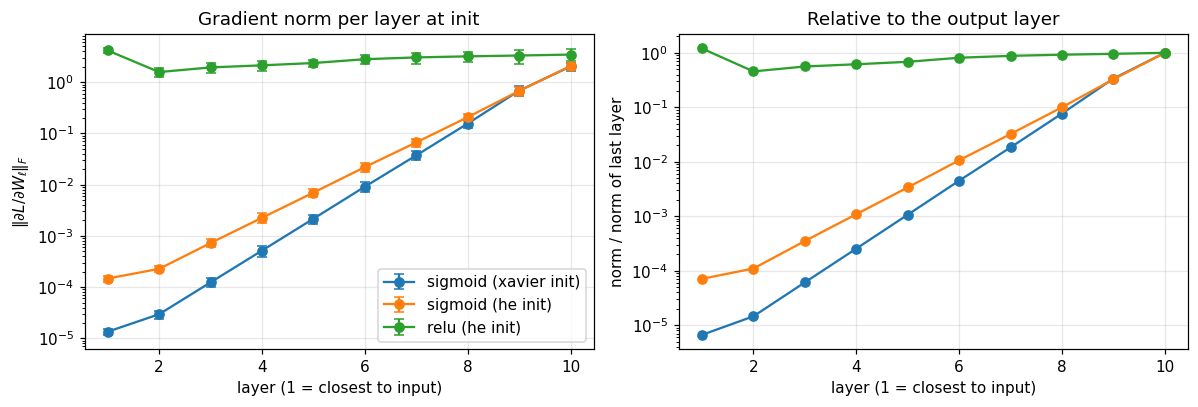

sigmoid (xavier init)  layer1 1.35e-05  layer10 2.04e+00  ratio 6.63e-06
sigmoid (he init)      layer1 1.47e-04  layer10 2.08e+00  ratio 7.09e-05
relu (he init)         layer1 4.17e+00  layer10 3.47e+00  ratio 1.20e+00


In [7]:
def grad_norms(act, init, seeds=5):
    out = []
    for s in range(seeds):
        set_seed(s)
        net = MLP([3072] + [256] * 9 + [10], act=act, init=init)
        net.loss(Xtr[:256].reshape(256, -1), Ytr[:256]); net.backward()
        out.append([l.dW.norm().item() for l in net.linears])
    return np.array(out)

configs = [('sigmoid', 'xavier'), ('sigmoid', 'he'), ('relu', 'he')]
GN = {f'{a} ({i} init)': grad_norms(a, i) for a, i in configs}
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for k, g in GN.items():
    ax[0].errorbar(np.arange(1, 11), g.mean(0), yerr=g.std(0), marker='o', capsize=3, label=k)
    ax[1].plot(np.arange(1, 11), g.mean(0) / g.mean(0)[-1], marker='o', label=k)
ax[0].set(yscale='log', xlabel='layer (1 = closest to input)', ylabel=r'$\|\partial L/\partial W_\ell\|_F$', title='Gradient norm per layer at init')
ax[1].set(yscale='log', xlabel='layer (1 = closest to input)', ylabel='norm / norm of last layer', title='Relative to the output layer')
ax[0].legend(); plt.tight_layout(); plt.show()
for k, g in GN.items():
    print(f'{k:22s} layer1 {g.mean(0)[0]:.2e}  layer10 {g.mean(0)[-1]:.2e}  ratio {g.mean(0)[0] / g.mean(0)[-1]:.2e}')

**Interpretation (d).** With **sigmoid**, the gradient norm shrinks roughly geometrically towards the input. Relative to the output layer, layer 1 receives about $7\times10^{-6}$ of the gradient with Xavier init ($1.4\times10^{-5}$ vs 2.0), so the first layers barely learn: the **vanishing gradient** problem. With **ReLU + He init**, the gradient norm is nearly flat across depth (3.5 at layer 10 vs 4.2 at layer 1, ratio about 1.2).
* **Why:** backpropagation multiplies the gradient at every layer by $W_\ell^\top\,\mathrm{diag}(\sigma'(z_\ell))$.
  * For the sigmoid, $\sigma'(z)=\sigma(z)(1-\sigma(z))\le 0.25$, so each layer shrinks the signal by at least about 4×. Nine hidden layers give about $4^{-9}\approx 4\times10^{-6}$, which matches the measured ratio. The sigmoid output is also not zero-centred (mean ≈ 0.5), which biases the pre-activations further.
  * For ReLU, the derivative is exactly 1 on the active half of the units. He initialisation ($\mathrm{Var}(W)=2/n_{in}$) compensates exactly for the half that are zeroed, so the variance of the backward signal is preserved layer after layer.
* The control curve (sigmoid with He init) is only about 10× better. The problem is therefore the activation's derivative, not the initialisation scale. This is why deep networks use ReLU-like activations with He initialisation (and, later, BN and residual connections).

---
## Task 2: Optimizers
### (a) SGD with momentum and Adam as `torch.optim.Optimizer` subclasses
SGD with momentum (PyTorch convention, no dampening): $b_t = \mu b_{t-1} + g_t$, $\theta_t = \theta_{t-1} - \eta b_t$.
Adam: $m_t=\beta_1 m_{t-1}+(1-\beta_1)g_t$, $v_t=\beta_2 v_{t-1}+(1-\beta_2)g_t^2$, $\hat m_t = m_t/(1-\beta_1^t)$, $\hat v_t = v_t/(1-\beta_2^t)$, $\theta_t=\theta_{t-1}-\eta\,\hat m_t/(\sqrt{\hat v_t}+\epsilon)$.
L2 weight decay is added to the gradient ($g \leftarrow g + \lambda\theta$), as in `torch.optim`.

optimizer                      max |theta_mine - theta_torch|  allclose
SGD (lr=0.05)                                        1.39e-16  True
SGD+momentum 0.9, wd 5e-4                            1.11e-16  True
Adam (lr=1e-3)                                       2.78e-17  True
Adam (lr=3e-3, wd 1e-4)                              8.33e-17  True


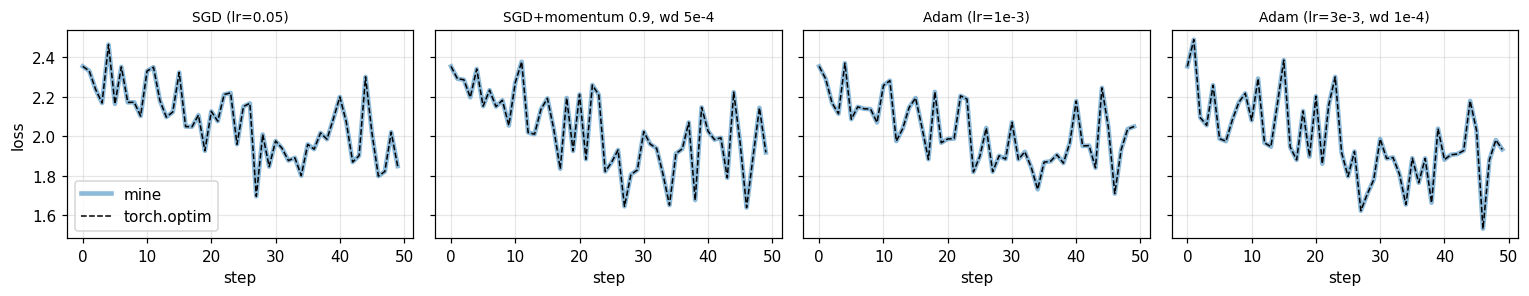

In [8]:
class MySGD(torch.optim.Optimizer):
    def __init__(self, params, lr, momentum=0.0, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, momentum=momentum, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            for p in group['params']:
                if p.grad is None:
                    continue
                d = p.grad
                if group['weight_decay'] != 0:
                    d = d.add(p, alpha=group['weight_decay'])
                if group['momentum'] != 0:
                    state = self.state[p]
                    if 'buf' not in state:
                        state['buf'] = d.clone()
                    else:
                        state['buf'].mul_(group['momentum']).add_(d)
                    d = state['buf']
                p.add_(d, alpha=-group['lr'])
        return loss


class MyAdam(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0):
        super().__init__(params, dict(lr=lr, betas=betas, eps=eps, weight_decay=weight_decay))

    @torch.no_grad()
    def step(self, closure=None):
        loss = None
        if closure is not None:
            with torch.enable_grad():
                loss = closure()
        for group in self.param_groups:
            b1, b2 = group['betas']
            for p in group['params']:
                if p.grad is None:
                    continue
                g = p.grad
                if group['weight_decay'] != 0:
                    g = g.add(p, alpha=group['weight_decay'])
                state = self.state[p]
                if not state:
                    state['t'] = 0
                    state['m'] = torch.zeros_like(p)
                    state['v'] = torch.zeros_like(p)
                state['t'] += 1
                t, m, v = state['t'], state['m'], state['v']
                m.mul_(b1).add_(g, alpha=1 - b1)
                v.mul_(b2).addcmul_(g, g, value=1 - b2)
                m_hat = m / (1 - b1 ** t)                 # bias correction
                v_hat = v / (1 - b2 ** t)
                p.addcdiv_(m_hat, v_hat.sqrt().add_(group['eps']), value=-group['lr'])
        return loss


def compare_optimizers(make_mine, make_ref, steps=50):
    set_seed(0)
    model = nn.Sequential(nn.Conv2d(3, 8, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2), nn.Flatten(),
                          nn.Linear(8 * 16 * 16, 10)).double().to(DEVICE)
    m1, m2 = copy.deepcopy(model), copy.deepcopy(model)
    o1, o2 = make_mine(m1.parameters()), make_ref(m2.parameters())
    gen = torch.Generator().manual_seed(1)
    l1s, l2s = [], []
    for _ in range(steps):
        j = torch.randint(0, len(Xtr), (32,), generator=gen).to(DEVICE)
        x, y = Xtr[j].double(), Ytr[j]
        for m, o, ls in [(m1, o1, l1s), (m2, o2, l2s)]:
            o.zero_grad(); l = F.cross_entropy(m(x), y); l.backward(); o.step(); ls.append(l.item())
    diffs = [(p - q).abs().max().item() for p, q in zip(m1.parameters(), m2.parameters())]
    same = all(torch.allclose(p, q) for p, q in zip(m1.parameters(), m2.parameters()))
    return max(diffs), same, l1s, l2s

tests = {
    'SGD (lr=0.05)':              (lambda p: MySGD(p, 0.05), lambda p: torch.optim.SGD(p, 0.05)),
    'SGD+momentum 0.9, wd 5e-4':  (lambda p: MySGD(p, 0.01, 0.9, 5e-4), lambda p: torch.optim.SGD(p, 0.01, momentum=0.9, weight_decay=5e-4)),
    'Adam (lr=1e-3)':             (lambda p: MyAdam(p, 1e-3), lambda p: torch.optim.Adam(p, 1e-3)),
    'Adam (lr=3e-3, wd 1e-4)':    (lambda p: MyAdam(p, 3e-3, weight_decay=1e-4), lambda p: torch.optim.Adam(p, 3e-3, weight_decay=1e-4)),
}
fig, ax = plt.subplots(1, 4, figsize=(14, 2.8), sharey=True)
print(f'{"optimizer":28s} {"max |theta_mine - theta_torch|":>32s}  allclose')
for a, (name, (mk1, mk2)) in zip(ax, tests.items()):
    d, same, l1s, l2s = compare_optimizers(mk1, mk2)
    print(f'{name:28s} {d:32.2e}  {same}')
    a.plot(l1s, lw=3, alpha=0.5, label='mine'); a.plot(l2s, 'k--', lw=1, label='torch.optim'); a.set_title(name, fontsize=9); a.set_xlabel('step')
ax[0].set_ylabel('loss'); ax[0].legend(); plt.tight_layout(); plt.show()

**Interpretation (a).** For all four settings (plain SGD, SGD with momentum and weight decay, Adam, Adam with weight decay), the parameters after 50 steps of `MySGD`/`MyAdam` differ from `torch.optim.SGD`/`torch.optim.Adam` by at most about $10^{-16}$. That is float64 round-off, and `torch.allclose` is `True`. The two loss curves lie exactly on top of each other.
* This confirms the update rules. `MySGD` follows PyTorch's convention: momentum buffer $b_t=\mu b_{t-1}+g_t$ initialised to $g_1$, no dampening, and L2 decay added to the gradient.
* For Adam, my form $\hat m_t/(\sqrt{\hat v_t}+\epsilon)$ is algebraically the same as PyTorch's $\frac{m_t/(1-\beta_1^t)}{\sqrt{v_t}/\sqrt{1-\beta_2^t}+\epsilon}$, so the only differences are floating-point evaluation order.
* Bias correction matters early. Without it, $m_1=0.1g_1$ and $v_1=0.001g_1^2$, so the first steps would be wrong by a factor $\sqrt{0.001}/0.1\approx0.32$.

### (b) Trajectories on $f(x,y)=\tfrac12(x^2+50y^2)$
The Hessian is diag(1, 50), so the condition number is 50. All three optimisers start from $(-9, 1.5)$ and take 100 steps. SGD and SGD with momentum ($\mu=0.9$) use the same learning rate $\eta=0.035$, just under the stability limit $2/50=0.04$ of plain GD. Adam uses $\eta=0.3$.

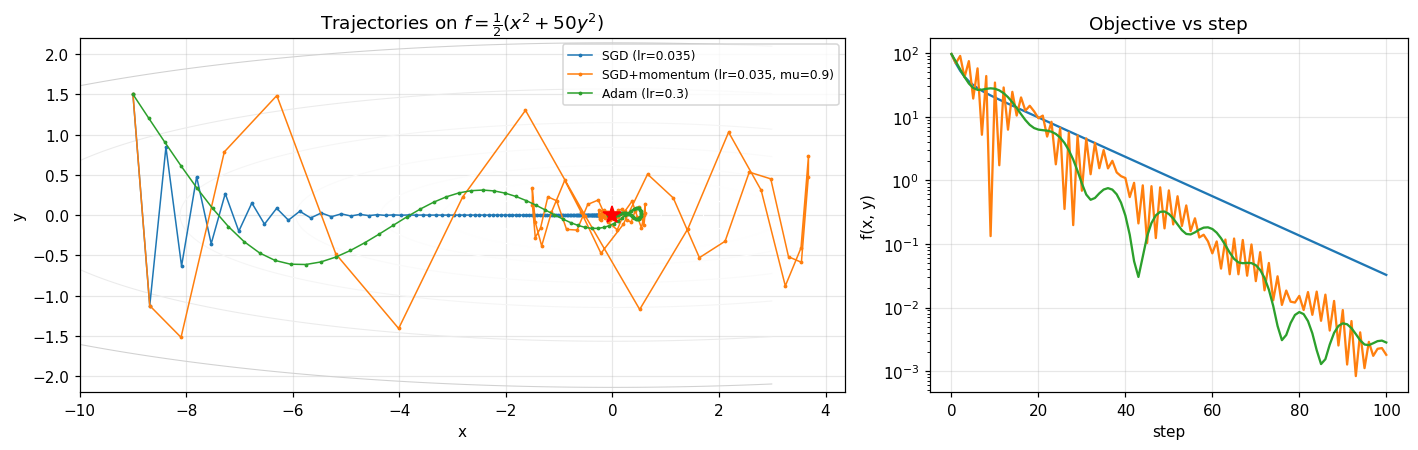

SGD (lr=0.035)                     f after 25/50/100 steps: 6.82e+00 / 1.15e+00 / 3.26e-02
SGD+momentum (lr=0.035, mu=0.9)    f after 25/50/100 steps: 6.67e+00 / 6.95e-01 / 1.80e-03
Adam (lr=0.3)                      f after 25/50/100 steps: 4.70e+00 / 2.96e-01 / 2.82e-03


In [9]:
def run_quadratic(make_opt, steps=100, start=(-9.0, 1.5)):
    p = torch.tensor(start, dtype=torch.float64, requires_grad=True)
    opt = make_opt([p]); path = [p.detach().clone().numpy()]
    for _ in range(steps):
        opt.zero_grad(); f = 0.5 * (p[0] ** 2 + 50 * p[1] ** 2); f.backward(); opt.step()
        path.append(p.detach().clone().numpy())
    return np.array(path)

fq = lambda P: 0.5 * (P[:, 0] ** 2 + 50 * P[:, 1] ** 2)
paths = {'SGD (lr=0.035)': run_quadratic(lambda p: MySGD(p, 0.035)),
         'SGD+momentum (lr=0.035, mu=0.9)': run_quadratic(lambda p: MySGD(p, 0.035, momentum=0.9)),
         'Adam (lr=0.3)': run_quadratic(lambda p: MyAdam(p, 0.3))}
xx, yy = np.meshgrid(np.linspace(-10, 3, 400), np.linspace(-2.2, 2.2, 400))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={'width_ratios': [1.6, 1]})
ax[0].contour(xx, yy, 0.5 * (xx ** 2 + 50 * yy ** 2), levels=np.logspace(-2, 2.6, 18), cmap='Greys', linewidths=0.7)
for (k, P), c in zip(paths.items(), ['C0', 'C1', 'C2']):
    ax[0].plot(P[:, 0], P[:, 1], '.-', color=c, ms=3, lw=1, label=k)
    ax[1].semilogy(np.maximum(fq(P), 1e-16), color=c, label=k)
ax[0].plot(0, 0, 'r*', ms=12); ax[0].set(xlabel='x', ylabel='y', title=r'Trajectories on $f=\frac{1}{2}(x^2+50y^2)$'); ax[0].legend(fontsize=8)
ax[1].set(xlabel='step', ylabel='f(x, y)', title='Objective vs step'); plt.tight_layout(); plt.show()
for k, P in paths.items():
    print(f'{k:34s} f after 25/50/100 steps: {fq(P)[25]:.2e} / {fq(P)[50]:.2e} / {fq(P)[100]:.2e}')

**Interpretation (b).** The Hessian is diag(1, 50), so $y$ is 50× more curved than $x$ (condition number 50).
* **SGD** (lr 0.035): in $y$ the update factor is $1-50\eta=-0.75$, so the iterate **zig-zags** across the narrow valley, with the oscillation shrinking by 0.75 per step. In $x$ the factor is $1-\eta=0.965$, so after the $y$ oscillation dies out, SGD **crawls slowly along the flat valley floor**. After 100 steps $f=3.3\times10^{-2}$. The learning rate cannot be raised to speed up $x$, because $\eta>2/50$ would make $y$ diverge. This is exactly how ill-conditioning slows gradient descent.
* **SGD with momentum** (same lr, $\mu=0.9$) accumulates velocity along the consistent $x$ direction, giving an effective step of about $\eta/(1-\mu)=10\eta$, while the alternating $y$ gradients partly cancel. With this lr it is under-damped: it makes large overshooting swings (reaching $x\approx+3.7$), but the swings decay. It reaches $f=1.8\times10^{-3}$, **18× lower than SGD**. A smaller lr or a lower $\mu$ would reduce the overshoot.
* **Adam** divides each coordinate by a running RMS of its gradient, so both coordinates move at a similar speed (about lr per step) regardless of curvature. The path is a **smooth curve** directly towards the optimum rather than a zig-zag, effectively removing the conditioning problem: $f=2.8\times10^{-3}$ after 100 steps. Near the minimum, a constant lr makes it oscillate slightly and the objective plateaus around $10^{-3}$, because the normalised step does not shrink with the gradient. A decaying lr would fix this.

### (c) Learning-rate sensitivity of a small CNN
The small CNN has three stages, each a 3×3 conv, ReLU and 2×2 max-pool, with 32/64/128 channels. A 2048 → 256 → 10 head follows. There is **no batch norm** here, so that the optimiser alone has to cope with the loss landscape. Every run uses a constant learning rate, batch size 128 and the same seed. Each optimiser gets a one-decade-spaced grid around its usual value. (On the CPU budget, training uses the first `t2_n` training images.)

In [10]:
class SmallCNN(nn.Module):
    def __init__(self, widths=(32, 64, 128), convs_per_stage=1, bn=False, dropout=0.0, hidden=256):
        super().__init__()
        layers, c = [], 3
        for w in widths:
            for _ in range(convs_per_stage):
                layers += [nn.Conv2d(c, w, 3, padding=1, bias=not bn)]
                layers += [nn.BatchNorm2d(w)] if bn else []
                layers += [nn.ReLU(inplace=True)]
                c = w
            layers.append(nn.MaxPool2d(2))
        self.features = nn.Sequential(*layers)
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(dropout), nn.Linear(c * 4 * 4, hidden),
                                  nn.ReLU(inplace=True), nn.Dropout(dropout), nn.Linear(hidden, 10))
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.kaiming_normal_(m.weight, nonlinearity='relu')
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.head(self.features(x))

print('SmallCNN (Task 2) parameters:', n_params(SmallCNN()))
LR_GRID = {'SGD': [0.01, 0.1, 1.0], 'SGD+momentum': [0.001, 0.01, 0.1], 'Adam': [1e-4, 1e-3, 1e-2]}
MAKE_OPT = {'SGD': lambda p, lr: MySGD(p, lr), 'SGD+momentum': lambda p, lr: MySGD(p, lr, momentum=0.9),
            'Adam': lambda p, lr: MyAdam(p, lr)}
n2 = BUDGET['t2_n']
R2 = {}
for opt_name, lrs in LR_GRID.items():
    for lr in lrs:
        def run(opt_name=opt_name, lr=lr):
            set_seed(0); m = SmallCNN()
            return fit(m, MAKE_OPT[opt_name](m.parameters(), lr), BUDGET['t2_epochs'], Xtr[:n2], Ytr[:n2],
                       n_train_eval=5000, tag=f'{opt_name} lr={lr}')
        R2[(opt_name, lr)] = cached(f't2c_{opt_name}_{lr}', run)

SmallCNN (Task 2) parameters: 620362
[SGD lr=0.01] ep  1/15  run-loss 1.794  train 1.575/0.450  val 1.613/0.440  (2s)
[SGD lr=0.01] ep  2/15  run-loss 1.435  train 1.560/0.470  val 1.622/0.447  (2s)
[SGD lr=0.01] ep  3/15  run-loss 1.303  train 1.285/0.542  val 1.355/0.526  (2s)
[SGD lr=0.01] ep  4/15  run-loss 1.208  train 1.246/0.565  val 1.330/0.542  (2s)
[SGD lr=0.01] ep  5/15  run-loss 1.131  train 1.153/0.597  val 1.255/0.569  (2s)
[SGD lr=0.01] ep  6/15  run-loss 1.067  train 0.999/0.652  val 1.127/0.609  (2s)
[SGD lr=0.01] ep  7/15  run-loss 1.011  train 0.956/0.664  val 1.107/0.621  (2s)
[SGD lr=0.01] ep  8/15  run-loss 0.965  train 0.920/0.684  val 1.095/0.616  (2s)
[SGD lr=0.01] ep  9/15  run-loss 0.920  train 0.949/0.669  val 1.149/0.615  (2s)
[SGD lr=0.01] ep 10/15  run-loss 0.879  train 0.832/0.721  val 1.040/0.636  (2s)
[SGD lr=0.01] ep 11/15  run-loss 0.844  train 0.814/0.715  val 1.031/0.650  (2s)
[SGD lr=0.01] ep 12/15  run-loss 0.804  train 0.820/0.710  val 1.063/0.6

optimizer           lr    val       lr    val       lr    val
SGD              1e-02  67.68    1e-01  10.00    1e+00  10.00
SGD+momentum     1e-03  67.84    1e-02  73.28    1e-01  10.00
Adam             1e-04  67.34    1e-03  72.10    1e-02  53.88


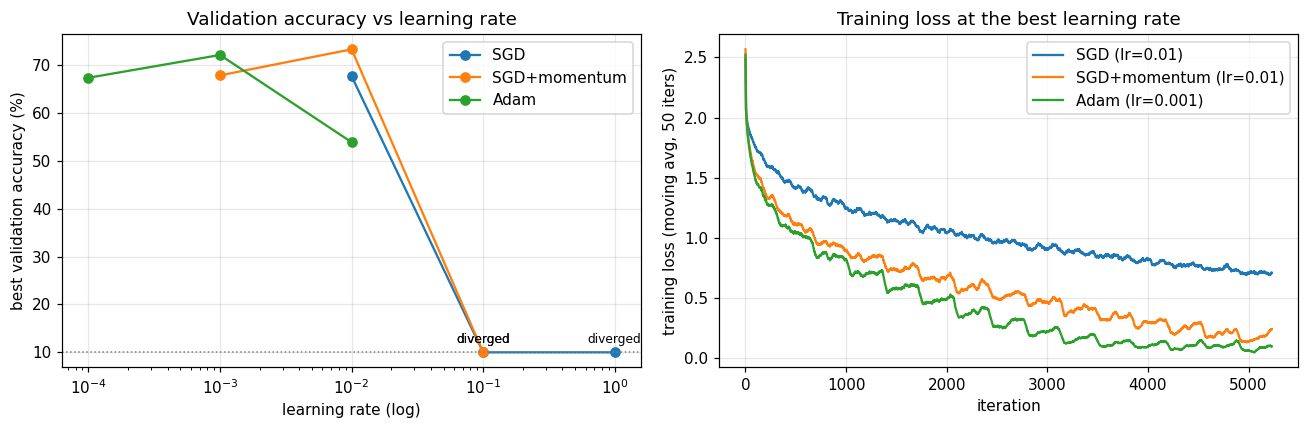

In [11]:
best_val = lambda H: max(H['val_acc']) if H['val_acc'] else 0.1
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
print(f'{"optimizer":14s} ' + '  '.join(f'{"lr":>7s} {"val":>6s}' for _ in range(3)))
for opt_name, lrs in LR_GRID.items():
    accs = [best_val(R2[(opt_name, lr)]) * 100 for lr in lrs]
    ax[0].semilogx(lrs, accs, 'o-', label=opt_name)
    for lr, a in zip(lrs, accs):
        if R2[(opt_name, lr)]['diverged']:
            ax[0].annotate('diverged', (lr, a), textcoords='offset points', xytext=(0, 6), fontsize=8, ha='center')
    print(f'{opt_name:14s} ' + '  '.join(f'{lr:7.0e} {a:6.2f}' for lr, a in zip(lrs, accs)))
    best_lr = lrs[int(np.argmax(accs))]
    il = np.array(R2[(opt_name, best_lr)]['iter_loss'])
    ax[1].plot(np.convolve(il, np.ones(50) / 50, mode='valid'), label=f'{opt_name} (lr={best_lr:g})')
ax[0].axhline(10, color='grey', ls=':', lw=1)
ax[0].set(xlabel='learning rate (log)', ylabel='best validation accuracy (%)', title='Validation accuracy vs learning rate')
ax[1].set(xlabel='iteration', ylabel='training loss (moving avg, 50 iters)', title='Training loss at the best learning rate')
ax[0].legend(); ax[1].legend(); plt.tight_layout(); plt.show()

**Interpretation (c).** Best validation accuracy for each learning rate (15 epochs, 45k images, constant lr, no BN):

| optimizer | lr = low | mid | high |
|---|---|---|---|
| SGD (0.01 / 0.1 / 1.0) | **67.7** | 10.0 (diverged) | 10.0 (diverged) |
| SGD + momentum (0.001 / 0.01 / 0.1) | 67.8 | **73.3** | 10.0 (diverged) |
| Adam (1e-4 / 1e-3 / 1e-2) | 67.3 | **72.1** | 53.9 |

* **Plain SGD** is the most fragile. Without BN, lr 0.1 already makes the loss blow up to NaN in the first epoch, so only the smallest rate works. 67.7% is also the lowest best result, because a stable lr is too small to make fast progress.
* **SGD with momentum** works at 0.001 and 0.01 and is best overall (73.3%), but diverges at 0.1. Momentum multiplies the effective step by $1/(1-\mu)=10$, so its usable range is shifted down by about a decade. SGD-m at 0.001 behaves almost identically to SGD at 0.01 (67.8 vs 67.7%, nearly the same curves).
* **Adam** is the least sensitive: no lr in a 100× range diverges, and the worst case (1e-2) still reaches 54% instead of collapsing to chance. Its per-parameter normalisation bounds the step size by roughly lr, regardless of the gradient scale. However, too large an Adam lr still trains badly (noisy, plateaus at high loss).
* In the training-loss plot at the best lr, Adam (1e-3) reduces the training loss fastest, reaching about 0.08 by epoch 15 with 98% train accuracy. SGD-m is next, and plain SGD is clearly slowest. Adam's fast training-loss decrease does **not** give the best validation accuracy: its validation loss rises after epoch 5 (overfitting), and SGD-m generalises slightly better (73.3 vs 72.1%).
* **Takeaway:** the learning rate is the most important hyper-parameter. Adaptive methods widen the safe range, but every optimiser needs it tuned (on a log scale).

---
## Task 3: Regularisation and residual connections
### (a) Regularisation on a 5k-image training set
The CNN here is a deeper variant with batch norm: two conv–BN–ReLU per stage (32/64/128 channels) and a 2048 → 256 → 10 head, about 0.8M parameters. It is trained on only the first 5,000 training images so that it overfits strongly. Shared training settings: SGD with momentum 0.9, lr 0.05 with cosine decay, batch 128, the same seed. Train accuracy is measured on the 5k training images **without augmentation** in eval mode, so the gap is measured fairly.

| Setting | What changes |
|---|---|
| baseline | nothing |
| weight decay | L2, λ = 5e-4 |
| dropout | p = 0.5 before both FC layers |
| flip+crop | random horizontal flip + 4-px padded random crop |
| cutout | one 16×16 zeroed square per image (my implementation) |
| mixup | α = 1.0, convex combination of image pairs and of their losses (my implementation) |
| all | all of the above together |

In [12]:
REG = {'baseline': {}, 'weight decay': dict(wd=5e-4), 'dropout': dict(dropout=0.5), 'flip+crop': dict(flip_crop=True),
       'cutout': dict(cut=True), 'mixup': dict(mixup=1.0),
       'all combined': dict(wd=5e-4, dropout=0.5, flip_crop=True, cut=True, mixup=1.0)}
X5k, Y5k = Xtr[:5000], Ytr[:5000]
R3a = {}
for name, c in REG.items():
    def run(c=c, name=name):
        set_seed(0)
        m = SmallCNN(convs_per_stage=2, bn=True, dropout=c.get('dropout', 0.0))
        opt = MySGD(m.parameters(), 0.05, momentum=0.9, weight_decay=c.get('wd', 0.0))
        return fit(m, opt, BUDGET['t3a_epochs'], X5k, Y5k, sched='cosine',
                   aug=make_aug(c.get('flip_crop', False), c.get('cut', False)),
                   mixup_alpha=c.get('mixup', 0.0), n_train_eval=5000, tag=name)
    R3a[name] = cached(f't3a_{name.replace(" ", "_").replace("+", "")}', run)
print('params:', n_params(SmallCNN(convs_per_stage=2, bn=True)))

[baseline] ep  1/60  run-loss 3.224  train 2.103/0.210  val 2.129/0.199  (1s)
[baseline] ep  2/60  run-loss 2.081  train 2.086/0.229  val 2.118/0.206  (1s)
[baseline] ep  3/60  run-loss 1.981  train 1.968/0.249  val 2.004/0.251  (1s)
[baseline] ep  4/60  run-loss 1.893  train 1.774/0.326  val 1.821/0.308  (1s)
[baseline] ep  5/60  run-loss 1.811  train 1.833/0.323  val 1.859/0.306  (1s)
[baseline] ep  6/60  run-loss 1.746  train 1.683/0.344  val 1.759/0.330  (1s)
[baseline] ep  7/60  run-loss 1.630  train 1.587/0.411  val 1.663/0.385  (1s)
[baseline] ep  8/60  run-loss 1.569  train 1.554/0.424  val 1.653/0.395  (1s)
[baseline] ep  9/60  run-loss 1.508  train 1.438/0.454  val 1.574/0.410  (1s)
[baseline] ep 10/60  run-loss 1.473  train 1.443/0.460  val 1.581/0.427  (1s)
[baseline] ep 11/60  run-loss 1.378  train 1.250/0.534  val 1.452/0.481  (1s)
[baseline] ep 12/60  run-loss 1.358  train 1.307/0.513  val 1.492/0.449  (1s)
[baseline] ep 13/60  run-loss 1.311  train 1.402/0.513  val 1.67

setting         train acc  val acc     gap  best val
baseline            99.98    61.06   38.92     61.24
weight decay       100.00    63.08   36.92     64.10
dropout             79.74    61.24   18.50     61.42
flip+crop           79.78    67.24   12.54     67.44
cutout              99.04    65.50   33.54     65.56
mixup               78.72    59.82   18.90     60.40
all combined        46.52    45.72    0.80     46.70


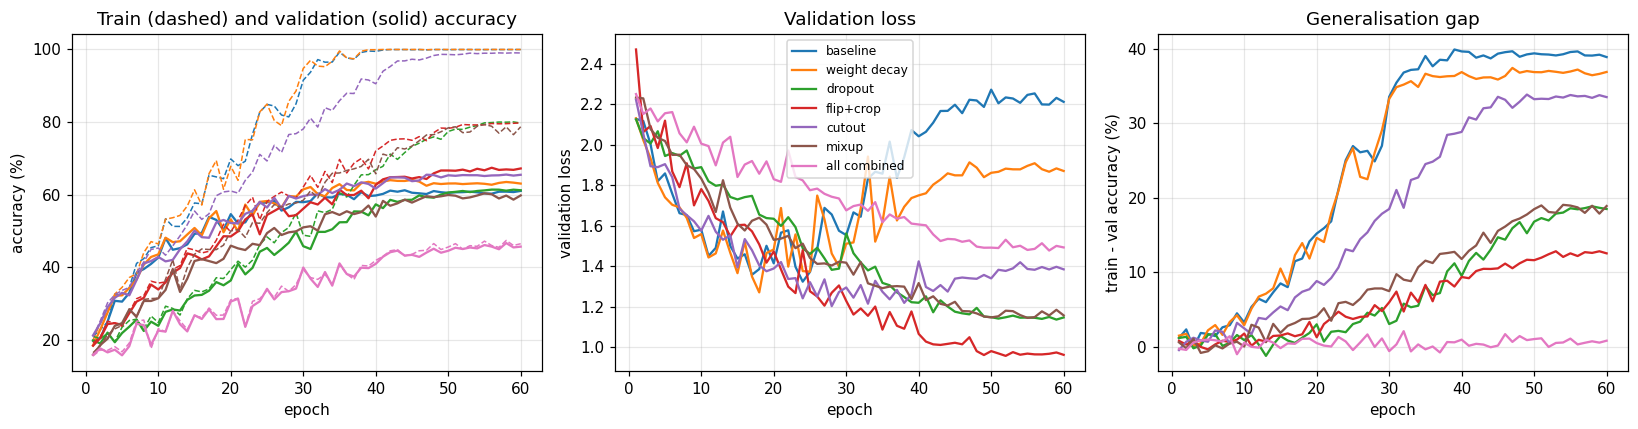

In [13]:
print(f'{"setting":14s} {"train acc":>10s} {"val acc":>8s} {"gap":>7s} {"best val":>9s}')
for name, H in R3a.items():
    tr, va = H['train_acc'][-1] * 100, H['val_acc'][-1] * 100
    print(f'{name:14s} {tr:10.2f} {va:8.2f} {tr - va:7.2f} {max(H["val_acc"]) * 100:9.2f}')
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for (name, H), c in zip(R3a.items(), plt.cm.tab10.colors):
    e = np.arange(1, len(H['val_acc']) + 1)
    ax[0].plot(e, np.array(H['train_acc']) * 100, '--', color=c, lw=1)
    ax[0].plot(e, np.array(H['val_acc']) * 100, '-', color=c, label=name)
    ax[1].plot(e, H['val_loss'], color=c, label=name)
    ax[2].plot(e, (np.array(H['train_acc']) - np.array(H['val_acc'])) * 100, color=c, label=name)
ax[0].set(xlabel='epoch', ylabel='accuracy (%)', title='Train (dashed) and validation (solid) accuracy')
ax[1].set(xlabel='epoch', ylabel='validation loss', title='Validation loss')
ax[2].set(xlabel='epoch', ylabel='train - val accuracy (%)', title='Generalisation gap')
ax[1].legend(fontsize=8); plt.tight_layout(); plt.show()

**Interpretation (a).** With only 5k images, the 0.8M-parameter baseline **memorises** the training set (100% train accuracy by about epoch 40, training loss 0.009). Validation accuracy plateaus at 61%, a **gap of 39 points**, and the validation loss rises steadily after epoch 20, a classic overfitting curve.
* **Weight decay** (λ = 5e-4) gives a small gain (63.1%, gap 36.9). With BN, the conv weights are scale-invariant, so L2 mostly acts by raising the effective learning rate. It does not stop memorisation.
* **Dropout** (0.5 in the FC head) halves the gap (18.5) but does not improve validation accuracy (61.2%). It only regularises the classifier head, not the conv features. It also makes training much slower (train accuracy only 80% after 60 epochs).
* **Flip + crop** is the clear winner: **67.2% validation, gap 12.5**, and the lowest validation loss (0.96). Translation and mirror invariance are true properties of natural images, so the augmentation effectively enlarges the dataset with realistic samples rather than just adding noise.
* **Cutout** also helps (65.5%, +4.4 over the baseline). The network must use the whole object rather than a single discriminative patch. But the model still nearly memorises the data (99% train), so the gap remains large (33.5).
* **Mixup** (α = 1) reduces the gap (18.9) but slightly lowers validation accuracy within 60 epochs (59.8%). Its training targets are soft mixtures, so the task is much harder and convergence is slower (training loss still 1.4 at epoch 60). It would need longer training to pay off.
* **All combined** has almost **no gap (0.8)** but only 45.7% validation accuracy, because it **under-fits**. Stacking five regularisers (plus dropout 0.5) on a small model with 60 epochs constrains it so much that it cannot even fit the training data (46.5% train), and the curves are still rising at epoch 60.
* **Conclusion:** a small gap alone is not the goal. Regularisation must be balanced against capacity and training time. Here, label-preserving geometric augmentation (flip + crop, possibly with cutout) gives the best bias–variance trade-off.

### (b) Plain vs residual networks of depth 6n+2
CIFAR-style networks (He et al., 2016) start with a 3×3 conv (16 channels), followed by three stages of $n$ basic blocks (two 3×3 conv–BN layers each) with 16/32/64 channels. The first block of stages 2 and 3 downsamples with stride 2. Global average pooling and a linear layer finish the network. Every conv uses Kaiming-normal initialisation.
The residual and plain networks are **identical except for the shortcut**: `ResBlock` adds `x` (or, for downsampling blocks, the parameter-free "option A" shortcut: stride-2 subsampling with zero-padded channels) before the final ReLU, and `plain` blocks do not. So both families have exactly the same number of parameters.

In [14]:
class Block(nn.Module):
    def __init__(self, c_in, c_out, stride, shortcut=True):
        super().__init__()
        self.c1 = nn.Conv2d(c_in, c_out, 3, stride, 1, bias=False); self.b1 = nn.BatchNorm2d(c_out)
        self.c2 = nn.Conv2d(c_out, c_out, 3, 1, 1, bias=False); self.b2 = nn.BatchNorm2d(c_out)
        self.shortcut, self.stride, self.pad = shortcut, stride, c_out - c_in

    def forward(self, x):
        out = self.b2(self.c2(F.relu(self.b1(self.c1(x)))))
        if self.shortcut:
            s = x[:, :, ::self.stride, ::self.stride] if self.stride > 1 else x
            if self.pad > 0:                                           # option A: zero-pad new channels
                s = F.pad(s, (0, 0, 0, 0, self.pad // 2, self.pad - self.pad // 2))
            out = out + s
        return F.relu(out)


class CifarNet(nn.Module):
    def __init__(self, n, shortcut=True, widths=(16, 32, 64)):
        super().__init__()
        self.stem = nn.Sequential(nn.Conv2d(3, widths[0], 3, 1, 1, bias=False), nn.BatchNorm2d(widths[0]), nn.ReLU(inplace=True))
        blocks, c = [], widths[0]
        for i, w in enumerate(widths):
            for k in range(n):
                blocks.append(Block(c, w, 2 if (i > 0 and k == 0) else 1, shortcut)); c = w
        self.blocks = nn.Sequential(*blocks)
        self.fc = nn.Linear(c, 10)
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)

    def forward(self, x):
        return self.fc(F.adaptive_avg_pool2d(self.blocks(self.stem(x)), 1).flatten(1))

for d in (8, 20, 56):
    n = (d - 2) // 6
    print(f'depth {d:2d} (n={n}): plain {n_params(CifarNet(n, False)):,} params, residual {n_params(CifarNet(n, True)):,} params')

depth  8 (n=1): plain 75,290 params, residual 75,290 params
depth 20 (n=3): plain 269,722 params, residual 269,722 params
depth 56 (n=9): plain 853,018 params, residual 853,018 params


Training settings: SGD with momentum 0.9, lr 0.1, cosine decay, weight decay 1e-4, batch 128, flip+crop augmentation, the same seed for every network. (On the CPU budget, training uses the first `t3b_n` images.)

In [15]:
n3 = BUDGET['t3b_n']
R3b = {}
for d in (8, 20, 56):
    for sc in (False, True):
        name = f'{"ResNet" if sc else "Plain"}-{d}'
        def run(d=d, sc=sc, name=name):
            set_seed(0); m = CifarNet((d - 2) // 6, shortcut=sc)
            opt = torch.optim.SGD(m.parameters(), 0.1, momentum=0.9, weight_decay=1e-4)
            return fit(m, opt, BUDGET['t3b_epochs'], Xtr[:n3], Ytr[:n3], sched='cosine',
                       aug=make_aug(flip_crop=True), n_train_eval=5000, tag=name)
        R3b[name] = cached(f't3b_{name}', run)

[Plain-8] ep  1/30  run-loss 1.573  train 1.380/0.509  val 1.442/0.491  (5s)
[Plain-8] ep  2/30  run-loss 1.145  train 1.530/0.544  val 1.637/0.530  (5s)
[Plain-8] ep  3/30  run-loss 0.991  train 0.998/0.645  val 1.052/0.641  (5s)
[Plain-8] ep  4/30  run-loss 0.895  train 1.036/0.642  val 1.109/0.636  (5s)
[Plain-8] ep  5/30  run-loss 0.822  train 1.118/0.622  val 1.212/0.611  (5s)
[Plain-8] ep  6/30  run-loss 0.774  train 0.752/0.734  val 0.797/0.723  (5s)
[Plain-8] ep  7/30  run-loss 0.719  train 0.786/0.732  val 0.860/0.713  (5s)
[Plain-8] ep  8/30  run-loss 0.688  train 0.959/0.699  val 1.056/0.679  (5s)
[Plain-8] ep  9/30  run-loss 0.662  train 0.691/0.763  val 0.764/0.752  (5s)
[Plain-8] ep 10/30  run-loss 0.630  train 0.654/0.774  val 0.741/0.754  (5s)
[Plain-8] ep 11/30  run-loss 0.606  train 0.628/0.786  val 0.720/0.757  (5s)
[Plain-8] ep 12/30  run-loss 0.589  train 0.596/0.784  val 0.672/0.772  (5s)
[Plain-8] ep 13/30  run-loss 0.566  train 0.558/0.802  val 0.642/0.774  (5s)

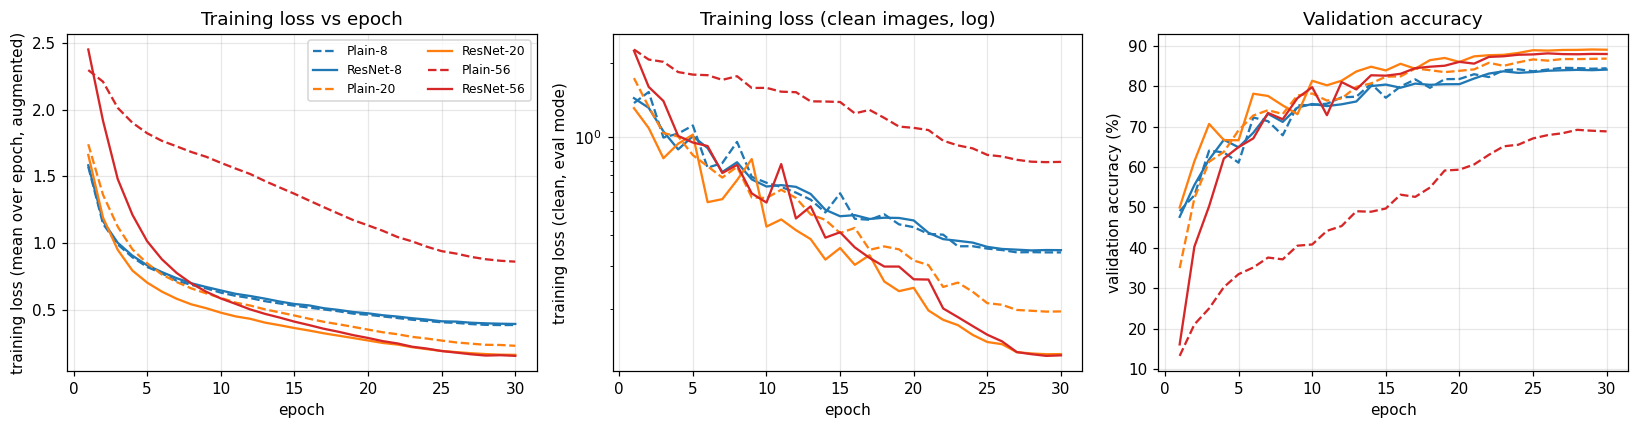

network     final train loss  train acc  val acc
Plain-8                0.388      88.06    84.42
ResNet-8               0.396      87.76    84.10
Plain-20               0.232      93.16    86.82
ResNet-20              0.164      95.28    89.02
Plain-56               0.862      72.10    68.82
ResNet-56              0.157      95.60    87.96


In [16]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
cols = {8: 'C0', 20: 'C1', 56: 'C3'}
for name, H in R3b.items():
    d = int(name.split('-')[1]); ls = '-' if name.startswith('ResNet') else '--'
    e = np.arange(1, len(H['train_loss_running']) + 1)
    ax[0].plot(e, H['train_loss_running'], ls, color=cols[d], label=name)
    ax[1].plot(e, H['train_loss'], ls, color=cols[d], label=name)
    ax[2].plot(e, np.array(H['val_acc']) * 100, ls, color=cols[d], label=name)
ax[0].set(xlabel='epoch', ylabel='training loss (mean over epoch, augmented)', title='Training loss vs epoch')
ax[1].set(xlabel='epoch', ylabel='training loss (clean, eval mode)', yscale='log', title='Training loss (clean images, log)')
ax[2].set(xlabel='epoch', ylabel='validation accuracy (%)', title='Validation accuracy')
ax[0].legend(fontsize=8, ncol=2); plt.tight_layout(); plt.show()
print(f'{"network":10s} {"final train loss":>17s} {"train acc":>10s} {"val acc":>8s}')
for name, H in R3b.items():
    print(f'{name:10s} {H["train_loss_running"][-1]:17.3f} {H["train_acc"][-1] * 100:10.2f} {H["val_acc"][-1] * 100:8.2f}')

**Interpretation (b).** The plain and residual nets have identical layers and parameter counts; only the shortcut differs.
* **Depth 8:** plain and residual are indistinguishable (final training loss 0.388 vs 0.396, validation 84.4 vs 84.1%). With only three blocks, optimisation is easy and the shortcut adds nothing.
* **Depth 20:** both train well, but the ResNet reaches a lower training loss (0.164 vs 0.232) and higher validation accuracy (89.0 vs 86.8%).
* **Depth 56:** the plain net shows the **degradation problem**. Its training loss is far *higher* than that of the shallower plain nets throughout training: 0.86 at epoch 30 vs 0.23 for Plain-20 and 0.39 for Plain-8. Its accuracy is only 72% (train) and 69% (validation).
  * This is **not overfitting**, since the *training* error is worse. It is an optimisation failure: a deeper plain network could in principle copy the 20-layer solution and set the extra layers to identity, but SGD cannot find that solution.
  * Even with BN and Kaiming init (so the gradients do not literally vanish, unlike in Task 1d), the composition of 54 non-linear layers produces a badly conditioned, rugged loss surface. It starts at chance (13% after epoch 1) and progresses slowly.
* **ResNet-56** trains easily: training loss 0.157 (the lowest of all), 95.6% train and 88.0% validation accuracy.
  * Each residual block computes $x + F(x)$, so representing the identity only requires $F\to0$, which is easy to learn.
  * The backward pass contains an identity term, $\partial x_{l+1}/\partial x_l = I + \partial F/\partial x_l$, so the gradient flows directly from the loss to every layer.
  * Deeper residual nets are therefore *at least as easy* to optimise as shallow ones, which is why depth helps only with shortcuts.
* ResNet-56 did not beat ResNet-20 on validation accuracy (88.0 vs 89.0%) within 30 epochs. Deeper ResNets typically need a longer schedule (about 160 epochs in the original paper) to realise their advantage.

---
## Task 4 (optional): The best CNN with ≤ 500k parameters and ≤ 20 epochs
**Design.** A residual network, 3 stages × 2 basic blocks with 24/48/96 channels (about 0.39M parameters), option-A shortcuts, BN, Kaiming init and GAP. Training: SGD with momentum 0.9, a one-cycle LR schedule (peak 0.1), weight decay 5e-4, label smoothing 0.1, flip+crop+cutout augmentation, batch 128.

**Ablation.** I remove or change one design choice at a time: (1) no shortcut (plain net), (2) no augmentation, (3) no weight decay, (4) Adam (peak lr 3e-3) instead of SGD with momentum. Ablation runs train on the first `t4_ablate_n` images for `t4_ablate_epochs` epochs and are compared on the **validation split**. The best configuration is then retrained on all 45k training images for `t4_final_epochs` (≤ 20) epochs, and the test set is used **exactly once** at the end.

In [17]:
T4_BASE = dict(shortcut=True, aug='flip+crop+cutout', wd=5e-4, opt='sgd')
T4_ABL = {'full model': {}, 'no shortcut': dict(shortcut=False), 'no augmentation': dict(aug='none'),
          'no weight decay': dict(wd=0.0), 'Adam instead of SGD': dict(opt='adam')}


def t4_train(cfg, n, epochs, tag):
    set_seed(0)
    m = CifarNet(2, shortcut=cfg['shortcut'], widths=(24, 48, 96))
    if cfg['opt'] == 'sgd':
        opt = torch.optim.SGD(m.parameters(), 0.1, momentum=0.9, weight_decay=cfg['wd'])
    else:
        opt = torch.optim.Adam(m.parameters(), 3e-3, weight_decay=cfg['wd'])
    aug = {'none': None, 'flip+crop': make_aug(True, False), 'flip+crop+cutout': make_aug(True, True)}[cfg['aug']]
    H = fit(m, opt, epochs, Xtr[:n], Ytr[:n], sched='onecycle', aug=aug, label_smoothing=0.1, n_train_eval=5000, tag=tag)
    return m, H

print('Task 4 model parameters:', f'{n_params(CifarNet(2, widths=(24, 48, 96))):,}', '(limit 500,000)')
R4 = {}
for name, change in T4_ABL.items():
    cfg = {**T4_BASE, **change}
    R4[name] = cached(f't4_ablate_{name.replace(" ", "_")}',
                      lambda cfg=cfg, name=name: t4_train(cfg, BUDGET['t4_ablate_n'], BUDGET['t4_ablate_epochs'], name)[1])

Task 4 model parameters: 386,626 (limit 500,000)
[full model] ep  1/20  run-loss 1.934  train 1.868/0.352  val 1.891/0.353  (13s)
[full model] ep  2/20  run-loss 1.680  train 1.469/0.494  val 1.524/0.480  (13s)
[full model] ep  3/20  run-loss 1.495  train 1.081/0.614  val 1.133/0.600  (13s)
[full model] ep  4/20  run-loss 1.360  train 1.056/0.637  val 1.098/0.617  (13s)
[full model] ep  5/20  run-loss 1.282  train 0.881/0.693  val 0.913/0.692  (13s)
[full model] ep  6/20  run-loss 1.215  train 0.868/0.693  val 0.925/0.684  (13s)
[full model] ep  7/20  run-loss 1.173  train 0.752/0.744  val 0.809/0.732  (13s)
[full model] ep  8/20  run-loss 1.138  train 0.752/0.741  val 0.786/0.734  (13s)
[full model] ep  9/20  run-loss 1.117  train 0.686/0.767  val 0.726/0.761  (13s)
[full model] ep 10/20  run-loss 1.089  train 0.728/0.752  val 0.768/0.740  (13s)
[full model] ep 11/20  run-loss 1.069  train 0.596/0.802  val 0.665/0.783  (13s)
[full model] ep 12/20  run-loss 1.048  train 0.578/0.814  va

configuration           train acc  val acc     val - full
full model                  91.84    88.50          +0.00
no shortcut                 91.36    88.36          -0.14
no augmentation            100.00    85.96          -2.54
no weight decay             91.12    86.40          -2.10
Adam instead of SGD         90.68    87.82          -0.68


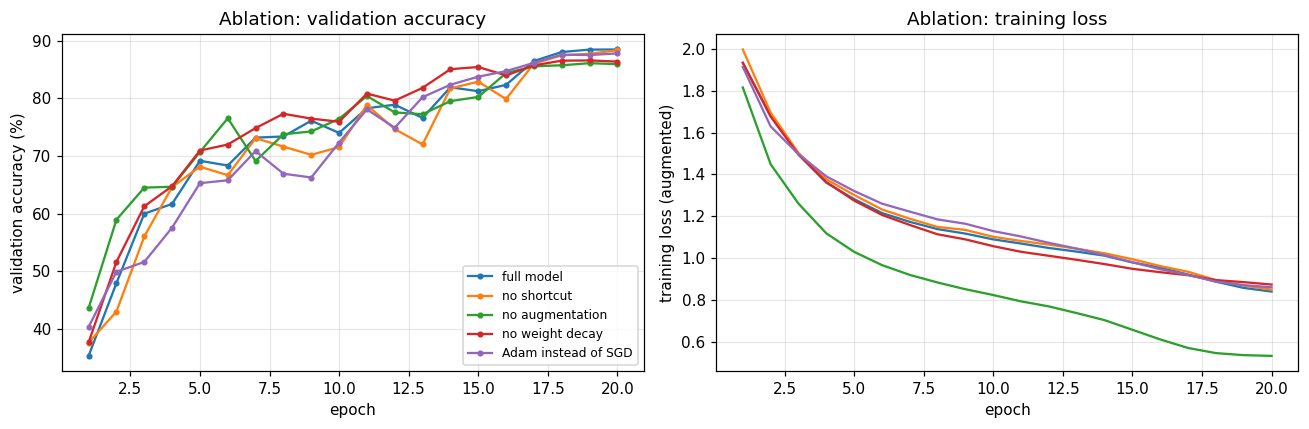

Selected configuration on the validation split: full model


In [18]:
print(f'{"configuration":22s} {"train acc":>10s} {"val acc":>8s} {"val - full":>14s}')
for name, H in R4.items():
    print(f'{name:22s} {H["train_acc"][-1] * 100:10.2f} {H["val_acc"][-1] * 100:8.2f} '
          f'{(H["val_acc"][-1] - R4["full model"]["val_acc"][-1]) * 100:+14.2f}')
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, H in R4.items():
    e = np.arange(1, len(H['val_acc']) + 1)
    ax[0].plot(e, np.array(H['val_acc']) * 100, 'o-', ms=3, label=name)
    ax[1].plot(e, H['train_loss_running'], label=name)
ax[0].set(xlabel='epoch', ylabel='validation accuracy (%)', title='Ablation: validation accuracy')
ax[1].set(xlabel='epoch', ylabel='training loss (augmented)', title='Ablation: training loss')
ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()
best_name = max(R4, key=lambda k: R4[k]['val_acc'][-1])
print('Selected configuration on the validation split:', best_name)

**Final model.** The selected configuration is retrained on the full 45k training split. The CIFAR-10 test set is loaded and evaluated **once**, here. The test accuracy is cached, so re-rendering the notebook does not evaluate the test set again.

[final] ep  1/20  run-loss 1.934  train 2.103/0.314  val 2.138/0.303  (13s)
[final] ep  2/20  run-loss 1.666  train 1.298/0.531  val 1.340/0.522  (13s)
[final] ep  3/20  run-loss 1.491  train 1.037/0.632  val 1.078/0.620  (13s)
[final] ep  4/20  run-loss 1.365  train 1.307/0.559  val 1.365/0.546  (13s)
[final] ep  5/20  run-loss 1.285  train 0.892/0.685  val 0.915/0.682  (13s)
[final] ep  6/20  run-loss 1.220  train 0.799/0.727  val 0.860/0.709  (13s)
[final] ep  7/20  run-loss 1.176  train 0.857/0.713  val 0.929/0.684  (13s)
[final] ep  8/20  run-loss 1.139  train 0.760/0.741  val 0.800/0.727  (13s)
[final] ep  9/20  run-loss 1.118  train 0.745/0.747  val 0.773/0.739  (13s)
[final] ep 10/20  run-loss 1.089  train 0.682/0.777  val 0.732/0.758  (13s)
[final] ep 11/20  run-loss 1.069  train 0.611/0.802  val 0.679/0.780  (13s)
[final] ep 12/20  run-loss 1.047  train 0.572/0.810  val 0.638/0.787  (13s)
[final] ep 13/20  run-loss 1.030  train 0.755/0.744  val 0.808/0.732  (13s)
[final] ep 1

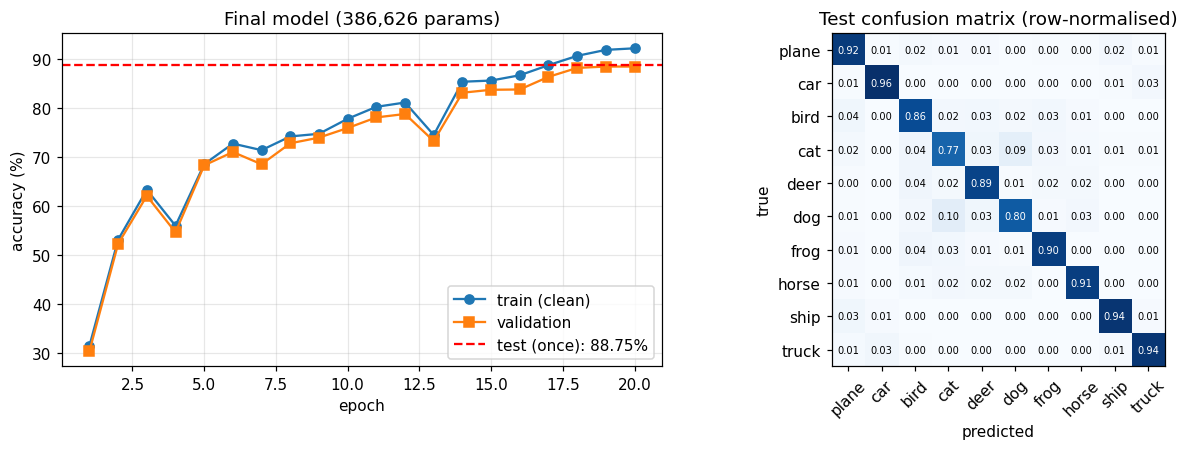

Final configuration: full model | params 386,626 | epochs 20
Validation accuracy: 88.38%   TEST ACCURACY (evaluated once): 88.75%
Per-class test accuracy: {'plane': 91.6, 'car': 96.0, 'bird': 85.6, 'cat': 76.6, 'deer': 88.8, 'dog': 80.1, 'frog': 90.4, 'horse': 90.7, 'ship': 94.0, 'truck': 93.7}


In [19]:
def final_run():
    cfg = {**T4_BASE, **T4_ABL[best_name]}
    m, H = t4_train(cfg, 45000, BUDGET['t4_final_epochs'], 'final')
    torch.save(m.state_dict(), f'{RESULTS}/t4_final.pt')
    # ---- the only use of the test set in this notebook ----
    test = torchvision.datasets.CIFAR10('./data', train=False, download=True)
    Xte = normalize(torch.tensor(test.data).permute(0, 3, 1, 2).float() / 255.).to(DEVICE)
    Yte = torch.tensor(test.targets).long().to(DEVICE)
    test_loss, test_acc = evaluate(m, Xte, Yte)
    with torch.no_grad():
        m.eval(); pred = torch.cat([m(Xte[i:i + 1000]).argmax(1) for i in range(0, 10000, 1000)])
    conf = torch.zeros(10, 10, dtype=torch.long)
    for t, p in zip(Yte.cpu(), pred.cpu()):
        conf[t, p] += 1
    return dict(config=best_name, H=H, test_loss=test_loss, test_acc=test_acc, conf=conf.tolist(),
                params=n_params(m))

FIN = cached('t4_final', final_run)
H = FIN['H']; e = np.arange(1, len(H['val_acc']) + 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(e, np.array(H['train_acc']) * 100, 'o-', label='train (clean)'); ax[0].plot(e, np.array(H['val_acc']) * 100, 's-', label='validation')
ax[0].axhline(FIN['test_acc'] * 100, color='r', ls='--', label=f'test (once): {FIN["test_acc"] * 100:.2f}%')
ax[0].set(xlabel='epoch', ylabel='accuracy (%)', title=f'Final model ({FIN["params"]:,} params)'); ax[0].legend()
C = np.array(FIN['conf']); Cn = C / C.sum(1, keepdims=True)
im = ax[1].imshow(Cn, cmap='Blues'); ax[1].grid(False)
ax[1].set(xticks=range(10), yticks=range(10), xticklabels=CLASSES, yticklabels=CLASSES, xlabel='predicted', ylabel='true', title='Test confusion matrix (row-normalised)')
plt.setp(ax[1].get_xticklabels(), rotation=45)
for i in range(10):
    for j in range(10):
        ax[1].text(j, i, f'{Cn[i, j]:.2f}', ha='center', va='center', fontsize=6.5, color='white' if Cn[i, j] > 0.5 else 'black')
plt.tight_layout(); plt.show()
print(f'Final configuration: {FIN["config"]} | params {FIN["params"]:,} | epochs {len(H["val_acc"])}')
print(f'Validation accuracy: {H["val_acc"][-1] * 100:.2f}%   TEST ACCURACY (evaluated once): {FIN["test_acc"] * 100:.2f}%')
print('Per-class test accuracy:', {c: round(float(Cn[i, i]) * 100, 1) for i, c in enumerate(CLASSES)})

**Interpretation (Task 4).** The final network is a 14-layer residual network (3 stages × 2 basic blocks, 24/48/96 channels, **386,626 parameters**). It was trained for 20 epochs with SGD-momentum, a one-cycle schedule, weight decay 5e-4, label smoothing 0.1 and flip + crop + cutout. It reaches **88.4% validation accuracy and 88.75% test accuracy**, evaluated once. Test and validation agree closely, which indicates the validation split was not over-fitted during tuning.

**Ablation (validation accuracy, 45k train images, 20 epochs, change relative to the full model):**
* **No augmentation: −2.5 points (86.0%)**, the largest effect. Without flip/crop/cutout, the model reaches **100% train accuracy** and overfits. Augmentation is the strongest regulariser for CIFAR-10 at this model size (consistent with Task 3a).
* **No weight decay: −2.1 points (86.4%).** With BN, weight decay keeps the weight norms small and so keeps the *effective* learning rate high late in training. Without it, the final accuracy is lower even though the training accuracy is similar.
* **Adam instead of SGD-momentum: −0.7 points (87.8%).** Adam converges comparably fast, but SGD-momentum with weight decay generalises slightly better. This is a common observation on image classification. Part of the gap is also because Adam's L2 decay is not decoupled (AdamW would be fairer).
* **No shortcut: −0.1 points (88.4%)**, negligible. With only 14 layers (6 blocks) the plain network is still easy to optimise, which matches Task 3b, where the shortcut mattered only at depth 56. Its validation accuracy was also slightly more erratic early in training.

The full configuration had the best validation accuracy, so it was selected and retrained on the 45k split. That final run used the same data and epochs as the ablation's "full model" run, so the small difference (88.38 vs 88.50%) shows the run-to-run variation from GPU nondeterminism. Differences below about 0.3 points in the ablation, such as "no shortcut", are therefore within noise.

On the test set, the confusion matrix shows the strongest classes are car (96%), ship (94%) and truck (94%). The hardest are **cat (77%) and dog (80%)**, which are mostly confused with each other. They are visually similar animal classes at 32×32 resolution.

Further gains within 500k parameters and 20 epochs would likely come from a wider first stage, mixed-precision training with a larger batch, or test-time flip augmentation.

_Utility (Colab): zip the cached results so they can be downloaded._

In [20]:
import shutil
shutil.make_archive('a02_results', 'zip', RESULTS)
print('saved a02_results.zip')

saved a02_results.zip
